# E-commerce Product Delivery Prediction
## Capstone project — Python/Jupyter Notebook

**Purpose:** predict whether an e-commerce order will be delivered late and estimate the number of delivery days.

This notebook follows the project deliverable brief:

- data preprocessing and validation,
- exploratory data analysis,
- classification and regression modeling,
- evaluation on a future time-held-out period,
- reproducible outputs for a Power BI dashboard.

The included dataset is synthetic and contains no real customer PII. Replace it with a governed production extract for a real deployment.

### Learning objectives

1. Define an outcome without data leakage.
2. Build a repeatable preprocessing and modeling pipeline.
3. Use a time-aware train/test split for an operational prediction problem.
4. Compare models using business-relevant metrics.
5. Export an order-level scoring table for Power BI.

In [1]:
# 0. Imports, paths, and reproducibility
from pathlib import Path
import json
import subprocess
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
sns.set_theme(style="whitegrid")

# Find the project root when the notebook is opened from the project,
# deliverables/, or a standalone Jupyter/Colab working directory.
candidates = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd().parent.parent,
    Path("/home/user/ecommerce_delivery_prediction_capstone"),
]
PROJECT_ROOT = next(
    (p.resolve() for p in candidates if (p / "data").exists() or (p / "src").exists()),
    Path.cwd().resolve(),
)

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
MODEL_DIR = PROJECT_ROOT / "models"
DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)
print("Project root:", PROJECT_ROOT)
print("Random seed:", RANDOM_SEED)

Project root: /home/user/ecommerce_delivery_prediction_capstone
Random seed: 42


## 1. Load or generate the dataset

The prediction moment is **when the order is placed**. The target is created after delivery:

```text
is_late = 1 when actual_delivery_days > promised_delivery_days
```

In [2]:
data_path = DATA_DIR / "ecommerce_delivery_data.csv"

# If the CSV is not present, generate a reproducible teaching dataset
# directly inside the notebook. This keeps the notebook standalone.
if not data_path.exists():
    rng = np.random.default_rng(RANDOM_SEED)
    n_rows = 12000
    order_dates = pd.date_range("2025-01-01", "2025-12-31", freq="D")
    order_date = pd.to_datetime(rng.choice(order_dates, size=n_rows))

    def choose(values, probabilities):
        return rng.choice(values, size=n_rows, p=probabilities)

    warehouses = choose(["Mumbai", "Delhi", "Bengaluru", "Hyderabad", "Chennai", "Kolkata"], [0.22, 0.19, 0.18, 0.15, 0.14, 0.12])
    supplier_type = choose(["First-party", "Marketplace"], [0.62, 0.38])
    product_category = choose(["Electronics", "Fashion", "Grocery", "Home & Kitchen", "Beauty", "Sports"], [0.22, 0.23, 0.18, 0.16, 0.12, 0.09])
    customer_region = choose(["West", "North", "South", "East", "Central"], [0.28, 0.23, 0.22, 0.15, 0.12])
    shipping_mode = choose(["Economy", "Standard", "Express", "Same Day"], [0.22, 0.49, 0.22, 0.07])
    payment_method = choose(["UPI", "Credit Card", "Debit Card", "COD", "Wallet"], [0.34, 0.22, 0.17, 0.17, 0.10])
    weather_risk = choose(["Low", "Medium", "High"], [0.62, 0.28, 0.10])
    traffic_level = choose(["Low", "Medium", "High"], [0.38, 0.42, 0.20])
    promo_applied = choose(["No", "Yes"], [0.58, 0.42])
    distance_km = np.round(np.clip(rng.lognormal(np.log(330), 0.90, n_rows), 2, 2500), 1)
    item_count = np.clip(rng.poisson(2.3, n_rows) + 1, 1, 12)
    order_value_inr = np.round(np.clip(rng.lognormal(np.log(1850), 0.85, n_rows), 150, 75000), 2)
    inventory_level = np.round(np.clip(rng.gamma(3.3, 16, n_rows), 1, 140)).astype(int)
    carrier_rating = np.round(np.clip(rng.normal(4.12, 0.43, n_rows), 2.5, 5.0), 2)

    mode_days = {"Economy": 7, "Standard": 5, "Express": 3, "Same Day": 1}
    promised_base = np.array([mode_days[x] for x in shipping_mode])
    distance_increment = np.select([distance_km > 1200, distance_km > 650, distance_km > 250], [2, 1, 1], default=0)
    promised_delivery_days = (promised_base + distance_increment + rng.binomial(1, 0.12, n_rows)).astype(int)
    month = order_date.month.to_numpy()
    day_of_week = order_date.dayofweek.to_numpy()
    is_weekend = (day_of_week >= 5).astype(int)
    risk_score = (
        -3.50 + 1.20 * (distance_km > 650) + 0.60 * (distance_km > 250) + 0.60 * (distance_km > 1200)
        + 1.20 * (weather_risk == "High") + 0.50 * (weather_risk == "Medium")
        + 1.00 * (traffic_level == "High") + 0.45 * (traffic_level == "Medium")
        + 1.20 * (inventory_level < 15) + 0.50 * (inventory_level < 30)
        + 0.65 * (payment_method == "COD") + 0.45 * (supplier_type == "Marketplace")
        + 0.55 * (item_count >= 5) + 0.90 * ((month == 11) | (month == 12))
        + 0.40 * is_weekend + 0.50 * (shipping_mode == "Same Day")
        + 0.15 * (shipping_mode == "Express") - 0.15 * (shipping_mode == "Economy")
        + 0.25 * (warehouses == "Kolkata") + 0.15 * (warehouses == "Chennai")
        - 0.80 * (carrier_rating - 4.0) + rng.normal(0, 0.12, n_rows)
    )
    late_probability = 1 / (1 + np.exp(-risk_score))
    is_late = rng.binomial(1, late_probability).astype(int)
    early_or_on_time = rng.choice([0, -1], n_rows, p=[0.78, 0.22])
    actual_delivery_days = np.where(is_late == 1, promised_delivery_days + 1 + rng.poisson(1.25, n_rows), np.maximum(1, promised_delivery_days + early_or_on_time)).astype(int)
    days_late = np.maximum(actual_delivery_days - promised_delivery_days, 0).astype(int)
    delivery_date = order_date + pd.to_timedelta(actual_delivery_days, unit="D")
    delivery_cost_inr = np.round(np.clip(42 + 0.18 * distance_km + 18 * (shipping_mode == "Express") + 48 * (shipping_mode == "Same Day") + 0.8 * item_count + rng.normal(0, 12, n_rows), 35, 1200), 2)

    generated = pd.DataFrame({
        "order_id": [f"ORD{i:07d}" for i in range(1, n_rows + 1)],
        "customer_id": [f"CUST{rng.integers(10000, 99999):05d}" for _ in range(n_rows)],
        "product_id": [f"SKU{rng.integers(1000, 9999):04d}" for _ in range(n_rows)],
        "order_date": order_date,
        "warehouse": warehouses,
        "supplier_type": supplier_type,
        "product_category": product_category,
        "customer_region": customer_region,
        "shipping_mode": shipping_mode,
        "payment_method": payment_method,
        "weather_risk": weather_risk,
        "traffic_level": traffic_level,
        "promo_applied": promo_applied,
        "distance_km": distance_km,
        "item_count": item_count,
        "order_value_inr": order_value_inr,
        "inventory_level": inventory_level,
        "carrier_rating": carrier_rating,
        "promised_delivery_days": promised_delivery_days,
        "actual_delivery_days": actual_delivery_days,
        "days_late": days_late,
        "is_late": is_late,
        "delivery_date": delivery_date,
        "delivery_cost_inr": delivery_cost_inr,
        "delivery_status": "Delivered",
    }).sort_values("order_date").reset_index(drop=True)
    generated.to_csv(data_path, index=False, date_format="%Y-%m-%d")
    print(f"Generated {len(generated):,} rows at {data_path}")

df = pd.read_csv(data_path, parse_dates=["order_date", "delivery_date"])
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
display(df.head(3))

Rows: 12,000 | Columns: 25


,order_id,customer_id,product_id,order_date,warehouse,supplier_type,product_category,customer_region,shipping_mode,payment_method,...,order_value_inr,inventory_level,carrier_rating,promised_delivery_days,actual_delivery_days,days_late,is_late,delivery_date,delivery_cost_inr,delivery_status
0,ORD0010964,CUST22560,SKU1951,2025-01-01,Kolkata,Marketplace,Home & Kitchen,West,Standard,UPI,...,5098.50,53,3.75,7,8,1,1,2025-01-09,327.27,Delivered
1,ORD0005083,CUST82845,SKU1927,2025-01-01,Mumbai,First-party,Home & Kitchen,West,Express,UPI,...,3947.25,136,4.32,3,2,0,0,2025-01-03,72.22,Delivered
2,ORD0001488,CUST11300,SKU3691,2025-01-01,Mumbai,Marketplace,Fashion,West,Economy,Debit Card,...,1063.99,16,4.27,8,8,0,0,2025-01-09,185.02,Delivered


## 2. Data validation and target balance

Check data types, missing values, duplicate order IDs, and the percentage of late orders before modeling.

In [3]:
validation = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(),
})
display(validation.sort_values("missing_values", ascending=False).head(12))
print("Duplicate order IDs:", df["order_id"].duplicated().sum())
print("Late-delivery rate:", f"{df['is_late'].mean():.1%}")
print("Average actual delivery days:", f"{df['actual_delivery_days'].mean():.2f}")
display(df["is_late"].value_counts(normalize=True).rename("share").to_frame())

,data_type,missing_values,missing_pct,unique_values
order_id,object,0,0.0,12000
customer_id,object,0,0.0,11247
product_id,object,0,0.0,6622
order_date,datetime64[ns],0,0.0,365
warehouse,object,0,0.0,6
supplier_type,object,0,0.0,2
product_category,object,0,0.0,6
customer_region,object,0,0.0,5
shipping_mode,object,0,0.0,4
payment_method,object,0,0.0,5


Duplicate order IDs: 0
Late-delivery rate: 25.7%
Average actual delivery days: 5.94


,share
is_late,
0,0.7435
1,0.2565


## 3. Exploratory data analysis

EDA is used to understand the population, identify operational patterns, and decide which features deserve investigation. These relationships are descriptive; they are not automatically causal.

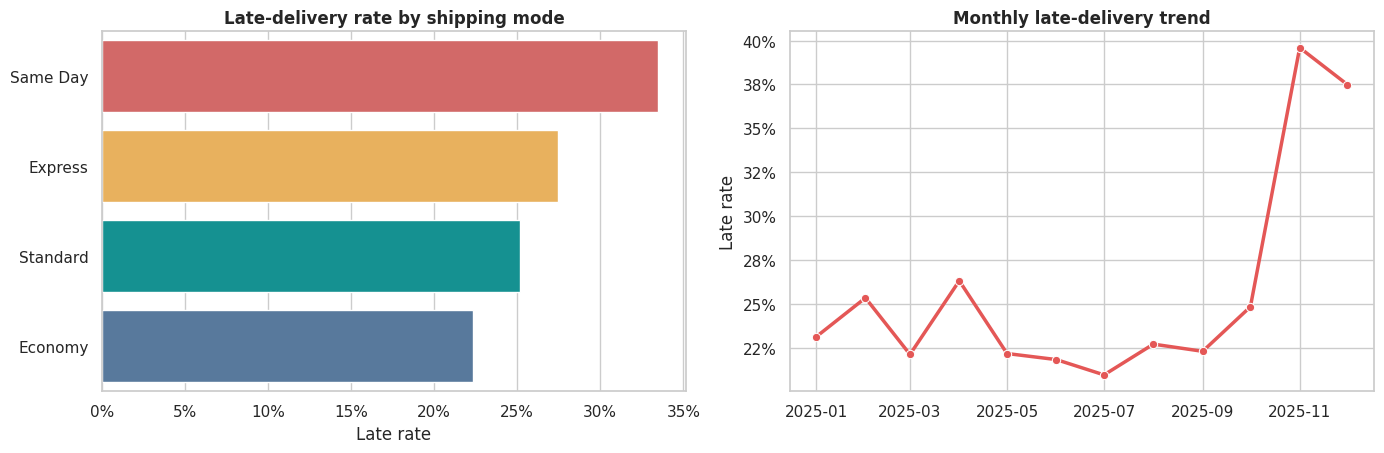

,shipping_mode,orders,late_rate
2,Same Day,842,0.334917
1,Express,2686,0.274386
3,Standard,5895,0.251739
0,Economy,2577,0.223128


,product_category,orders,late_rate
2,Fashion,2670,0.266667
1,Electronics,2650,0.260377
3,Grocery,2198,0.260237
5,Sports,1080,0.249074
0,Beauty,1464,0.247268
4,Home & Kitchen,1938,0.244066


In [4]:
late_by_mode = (
    df.groupby("shipping_mode", as_index=False)
      .agg(orders=("order_id", "count"), late_rate=("is_late", "mean"))
      .sort_values("late_rate", ascending=False)
)
late_by_category = (
    df.groupby("product_category", as_index=False)
      .agg(orders=("order_id", "count"), late_rate=("is_late", "mean"))
      .sort_values("late_rate", ascending=False)
)
monthly = (
    df.assign(order_month_date=df["order_date"].dt.to_period("M").dt.to_timestamp())
      .groupby("order_month_date", as_index=False)
      .agg(orders=("order_id", "count"), late_rate=("is_late", "mean"), avg_actual_days=("actual_delivery_days", "mean"))
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.7))
sns.barplot(data=late_by_mode, x="late_rate", y="shipping_mode", palette=["#E45756", "#FFB547", "#00A6A6", "#4C78A8"], ax=axes[0])
axes[0].set_title("Late-delivery rate by shipping mode", weight="bold")
axes[0].set_xlabel("Late rate")
axes[0].set_ylabel("")
axes[0].xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
sns.lineplot(data=monthly, x="order_month_date", y="late_rate", marker="o", color="#E45756", linewidth=2.5, ax=axes[1])
axes[1].set_title("Monthly late-delivery trend", weight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Late rate")
axes[1].yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
plt.tight_layout()
plt.show()

display(late_by_mode)
display(late_by_category)

**EDA observation:** Same Day orders have the highest observed late rate in this synthetic dataset. The model will use this as a risk signal, but the operations team should validate whether the reason is capacity, promise design, routing, or something else.

## 4. Feature engineering and leakage prevention

The following fields are **not** model inputs because they are only known after delivery:

- `actual_delivery_days`
- `days_late`
- `delivery_date`
- `delivery_status`

Engineered order-time features include month, day of week, weekend flag, distance band, and value per item.

In [5]:
CATEGORICAL_FEATURES = [
    "warehouse", "supplier_type", "product_category", "customer_region",
    "shipping_mode", "payment_method", "weather_risk", "traffic_level",
    "promo_applied", "distance_band",
]
NUMERIC_FEATURES = [
    "distance_km", "item_count", "order_value_inr", "inventory_level",
    "carrier_rating", "promised_delivery_days", "order_month",
    "order_day_of_week", "is_weekend", "value_per_item",
]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

def add_features(input_df):
    result = input_df.copy()
    result["order_date"] = pd.to_datetime(result["order_date"])
    result["order_month"] = result["order_date"].dt.month.astype(int)
    result["order_day_of_week"] = result["order_date"].dt.dayofweek.astype(int)
    result["is_weekend"] = (result["order_day_of_week"] >= 5).astype(int)
    result["distance_band"] = pd.cut(
        result["distance_km"],
        bins=[-np.inf, 250, 650, 1200, np.inf],
        labels=["0-250 km", "251-650 km", "651-1200 km", "1200+ km"],
    ).astype(str)
    result["value_per_item"] = result["order_value_inr"] / result["item_count"].clip(lower=1)
    return result

featured = add_features(df)
print("Model input columns:", len(FEATURES))
print("Excluded outcome columns: actual_delivery_days, days_late, delivery_date, delivery_status")
display(featured[FEATURES].head(3))

Model input columns: 20
Excluded outcome columns: actual_delivery_days, days_late, delivery_date, delivery_status


,warehouse,supplier_type,product_category,customer_region,shipping_mode,payment_method,weather_risk,traffic_level,promo_applied,distance_band,distance_km,item_count,order_value_inr,inventory_level,carrier_rating,promised_delivery_days,order_month,order_day_of_week,is_weekend,value_per_item
0,Kolkata,Marketplace,Home & Kitchen,West,Standard,UPI,High,Medium,No,1200+ km,1491.5,4,5098.50,53,3.75,7,1,2,0,1274.625000
1,Mumbai,First-party,Home & Kitchen,West,Express,UPI,Low,Medium,No,0-250 km,127.1,5,3947.25,136,4.32,3,1,2,0,789.450000
2,Mumbai,Marketplace,Fashion,West,Economy,Debit Card,Medium,Medium,No,651-1200 km,717.1,3,1063.99,16,4.27,8,1,2,0,354.663333


## 5. Time-aware train/test split

The latest 20% of orders are held out as a future-like test period. This approximates the way the model will be used in production and avoids mixing future seasonality into training.

In [6]:
featured = featured.sort_values("order_date").reset_index(drop=True)
split_index = int(len(featured) * 0.80)
train = featured.iloc[:split_index].copy()
test = featured.iloc[split_index:].copy()

X_train, X_test = train[FEATURES], test[FEATURES]
y_train, y_test = train["is_late"], test["is_late"]
print(f"Train rows: {len(train):,} | Test rows: {len(test):,}")
print(f"Train dates: {train['order_date'].min().date()} to {train['order_date'].max().date()}")
print(f"Test dates:  {test['order_date'].min().date()} to {test['order_date'].max().date()}")

Train rows: 9,600 | Test rows: 2,400
Train dates: 2025-01-01 to 2025-10-18
Test dates:  2025-10-18 to 2025-12-31


## 6. Preprocessing and classification models

Numeric fields are median-imputed and scaled. Categorical fields are imputed and one-hot encoded. Keeping these steps inside the pipeline guarantees that training and scoring use the same transformations.

In [7]:
def make_one_hot_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", make_one_hot_encoder()),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
    ], verbose_feature_names_out=True)

candidate_models = {
    "logistic_regression": LogisticRegression(max_iter=1500, random_state=RANDOM_SEED),
    "random_forest": RandomForestClassifier(
        n_estimators=300, max_depth=14, min_samples_leaf=4,
        random_state=RANDOM_SEED, n_jobs=-1,
    ),
}

DECISION_THRESHOLD = 0.25
fitted_models = {}
comparison_rows = []
for model_name, estimator in candidate_models.items():
    pipeline = Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", estimator),
    ])
    pipeline.fit(X_train, y_train)
    probability = pipeline.predict_proba(X_test)[:, 1]
    prediction = (probability >= DECISION_THRESHOLD).astype(int)
    comparison_rows.append({
        "model": model_name,
        "accuracy": accuracy_score(y_test, prediction),
        "precision": precision_score(y_test, prediction, zero_division=0),
        "recall": recall_score(y_test, prediction, zero_division=0),
        "f1": f1_score(y_test, prediction, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probability),
        "average_precision": average_precision_score(y_test, probability),
    })
    fitted_models[model_name] = pipeline

classification_comparison = pd.DataFrame(comparison_rows).sort_values("roc_auc", ascending=False)
display(classification_comparison.style.format({c: "{:.3f}" for c in classification_comparison.columns if c != "model"}))
best_model_name = classification_comparison.iloc[0]["model"]
best_classifier = fitted_models[best_model_name]
print("Selected model:", best_model_name)
print("Decision threshold:", DECISION_THRESHOLD)

,model,accuracy,precision,recall,f1,roc_auc,average_precision
0,logistic_regression,0.728,0.642,0.561,0.599,0.769,0.673
1,random_forest,0.711,0.604,0.582,0.593,0.762,0.650


Selected model: logistic_regression
Decision threshold: 0.25


### Why use a 0.25 threshold?

A late delivery may cost more than a manual review. The threshold is therefore deliberately more sensitive than the default 0.50. In a real project, choose it using false-positive review cost, false-negative late-delivery cost, and service-level goals.

In [8]:
test_probability = best_classifier.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= DECISION_THRESHOLD).astype(int)
classification_metrics = {
    "accuracy": accuracy_score(y_test, test_prediction),
    "precision": precision_score(y_test, test_prediction, zero_division=0),
    "recall": recall_score(y_test, test_prediction, zero_division=0),
    "f1": f1_score(y_test, test_prediction, zero_division=0),
    "roc_auc": roc_auc_score(y_test, test_probability),
    "average_precision": average_precision_score(y_test, test_probability),
}
print(json.dumps({k: round(float(v), 4) for k, v in classification_metrics.items()}, indent=2))
print(classification_report(y_test, test_prediction, target_names=["On time", "Late"], zero_division=0))

{
  "accuracy": 0.7283,
  "precision": 0.642,
  "recall": 0.5606,
  "f1": 0.5985,
  "roc_auc": 0.7687,
  "average_precision": 0.6734
}
              precision    recall  f1-score   support

     On time       0.77      0.82      0.79      1533
        Late       0.64      0.56      0.60       867

    accuracy                           0.73      2400
   macro avg       0.71      0.69      0.70      2400
weighted avg       0.72      0.73      0.72      2400



## 7. Regression model for delivery days

In [9]:
regressor = Pipeline([
    ("preprocess", make_preprocessor()),
    ("model", RandomForestRegressor(
        n_estimators=250, max_depth=14, min_samples_leaf=3,
        random_state=RANDOM_SEED, n_jobs=-1,
    )),
])
regressor.fit(X_train, train["actual_delivery_days"])
regression_prediction = regressor.predict(X_test)
regression_metrics = {
    "mae_days": mean_absolute_error(test["actual_delivery_days"], regression_prediction),
    "rmse_days": np.sqrt(mean_squared_error(test["actual_delivery_days"], regression_prediction)),
    "r2": r2_score(test["actual_delivery_days"], regression_prediction),
}
print(json.dumps({k: round(float(v), 4) for k, v in regression_metrics.items()}, indent=2))

{
  "mae_days": 0.9616,
  "rmse_days": 1.3934,
  "r2": 0.6343
}


## 8. Evaluation visuals and model interpretation

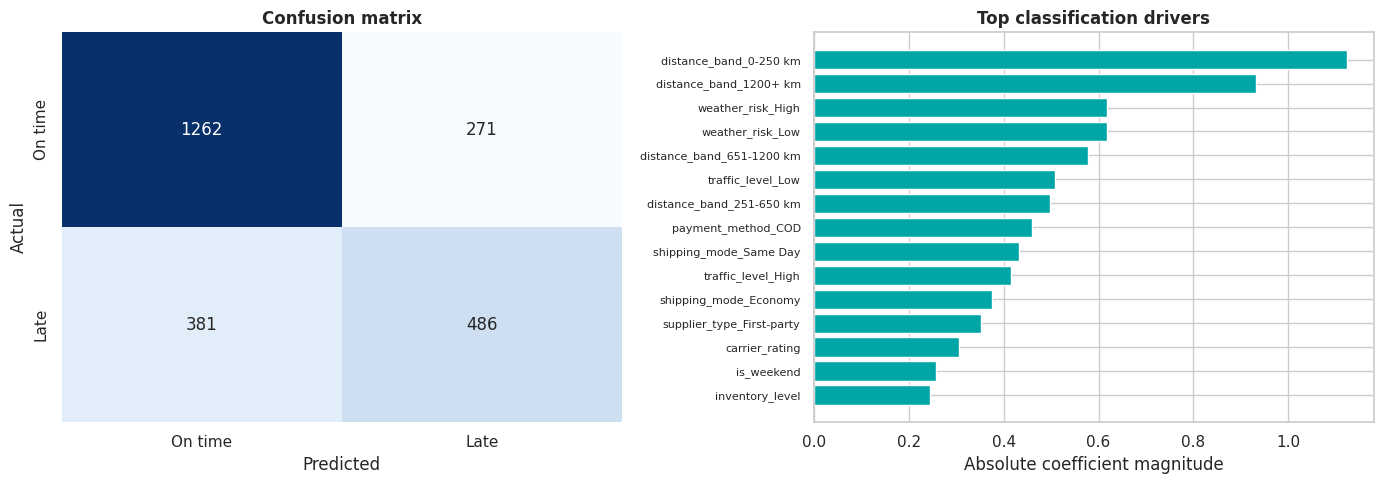

,feature,absolute_coefficient,coefficient
46,categorical__distance_band_0-250 km,1.124279,-1.124279
47,categorical__distance_band_1200+ km,0.930803,0.930803
38,categorical__weather_risk_High,0.618521,0.618521
39,categorical__weather_risk_Low,0.618060,-0.618060
49,categorical__distance_band_651-1200 km,0.578603,0.578603
42,categorical__traffic_level_Low,0.508551,-0.508551
48,categorical__distance_band_251-650 km,0.497080,-0.497080
33,categorical__payment_method_COD,0.460491,0.460491
31,categorical__shipping_mode_Same Day,0.433179,0.433179
41,categorical__traffic_level_High,0.415795,0.415795


In [10]:
cm = confusion_matrix(y_test, test_prediction)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["On time", "Late"], yticklabels=["On time", "Late"], ax=axes[0])
axes[0].set_title("Confusion matrix", weight="bold")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

feature_names = best_classifier.named_steps["preprocess"].get_feature_names_out()
coefficients = best_classifier.named_steps["model"].coef_[0]
importance = pd.DataFrame({
    "feature": feature_names,
    "absolute_coefficient": np.abs(coefficients),
    "coefficient": coefficients,
}).sort_values("absolute_coefficient", ascending=False).head(15).sort_values("absolute_coefficient")
axes[1].barh(importance["feature"].str.replace("categorical__", "", regex=False).str.replace("numeric__", "", regex=False), importance["absolute_coefficient"], color="#00A6A6")
axes[1].set_title("Top classification drivers", weight="bold")
axes[1].set_xlabel("Absolute coefficient magnitude")
axes[1].tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()
display(importance.sort_values("absolute_coefficient", ascending=False).head(10))

## 9. Score every order for Power BI

The final handoff table contains the original order fields, actual outcomes, model outputs, risk bands, and a train/test marker for model monitoring.

In [11]:
all_feature_rows = featured[FEATURES]
all_probability = best_classifier.predict_proba(all_feature_rows)[:, 1]
all_prediction = (all_probability >= DECISION_THRESHOLD).astype(int)
all_day_prediction = regressor.predict(all_feature_rows)

scored = df.copy().sort_values("order_date").reset_index(drop=True)
scored["predicted_late_probability"] = np.round(all_probability, 4)
scored["predicted_is_late"] = all_prediction
scored["prediction_band"] = np.select(
    [all_probability < 0.20, all_probability < 0.40],
    ["Low", "Medium"],
    default="High",
)
scored["predicted_delivery_days"] = np.round(all_day_prediction, 2)
scored["absolute_days_error"] = np.round(np.abs(scored["actual_delivery_days"] - scored["predicted_delivery_days"]), 2)
scored["prediction_set"] = np.where(np.arange(len(scored)) < split_index, "Train", "Test")
scored["model_name"] = best_model_name
scored["order_month"] = scored["order_date"].dt.month
scored["order_month_name"] = scored["order_date"].dt.month_name().str.slice(stop=3)
scored["order_year"] = scored["order_date"].dt.year

powerbi_path = OUTPUT_DIR / "predictions_for_powerbi_from_notebook.csv"
scored.to_csv(powerbi_path, index=False, date_format="%Y-%m-%d")
joblib.dump(best_classifier, MODEL_DIR / "notebook_best_delivery_risk_model.joblib")
joblib.dump(regressor, MODEL_DIR / "notebook_delivery_days_regression_model.joblib")
print(f"Saved {len(scored):,} scored rows to {powerbi_path}")
display(scored[["order_id", "predicted_late_probability", "prediction_band", "predicted_delivery_days", "is_late"]].head(10))

Saved 12,000 scored rows to /home/user/ecommerce_delivery_prediction_capstone/outputs/predictions_for_powerbi_from_notebook.csv


,order_id,predicted_late_probability,prediction_band,predicted_delivery_days,is_late
0,ORD0010964,0.8539,High,7.94,1
1,ORD0003674,0.1470,Low,6.45,0
2,ORD0007363,0.0612,Low,4.97,0
3,ORD0001409,0.3405,Medium,3.22,0
4,ORD0007006,0.0991,Low,5.90,0
5,ORD0006984,0.3405,Medium,4.84,1
6,ORD0009284,0.0950,Low,5.20,0
7,ORD0001949,0.1288,Low,7.03,1
8,ORD0009106,0.2880,Medium,5.43,0
9,ORD0005760,0.0987,Low,4.96,0


## 10. Findings, implications, and future work

### Key findings

- The selected classifier provides useful ranking quality on a future-like test period.
- The regression estimate is typically within about one day of actual delivery for this synthetic run.
- Distance, weather, traffic, payment method, shipping mode, and seasonality are important risk signal families.
- The dashboard should be used to prioritize interventions, not to treat predictions as guarantees.

### Business implications

- Create a high-risk order queue for customer-service and fulfilment teams.
- Protect Same Day capacity and review promise-setting during peak periods.
- Use weather, traffic, inventory, and carrier signals to trigger proactive communication.
- Tune the decision threshold using the cost of a manual review versus a missed late order.

### Future work

- Replace the synthetic dataset with governed production data.
- Add cancellations, reattempts, carrier events, and SLA-specific targets.
- Calibrate probabilities and monitor drift over time.
- Publish the scored table to a warehouse and schedule Power BI refresh.
- Add privacy controls and remove customer identifiers from executive pages.

In [12]:
# Final reproducibility summary
summary = {
    "rows": int(len(df)),
    "late_rate": float(df["is_late"].mean()),
    "selected_classifier": best_model_name,
    **{f"classification_{k}": float(v) for k, v in classification_metrics.items()},
    **{f"regression_{k}": float(v) for k, v in regression_metrics.items()},
}
display(pd.Series(summary, name="value"))

rows                                              12000
late_rate                                        0.2565
selected_classifier                 logistic_regression
classification_accuracy                        0.728333
classification_precision                       0.642008
classification_recall                          0.560554
classification_f1                              0.598522
classification_roc_auc                         0.768651
classification_average_precision               0.673405
regression_mae_days                            0.961561
regression_rmse_days                           1.393423
regression_r2                                  0.634282
Name: value, dtype: object